In [ ]:
import os
# os.environ['CUDA_VISIBLE_DEVICES'] = '3'

import torch
import torchvision.transforms as transforms
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt

from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader
from torch.optim import Adam
import torchvision
import torchvision.models as models
from torchsummary import summary

torch.manual_seed(1)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Data

In [ ]:
batch_size = 16
train_transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize([0.4914, 0.4822, 0.4465],
                             [0.2470, 0.2435, 0.2616]),
    ])

val_transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize([0.4914, 0.4822, 0.4465],
                             [0.2470, 0.2435, 0.2616])
    ])

train_set = CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=train_transform
)

val_set = CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=val_transform
)

trainloader = DataLoader(
    train_set,
    batch_size=batch_size,
    shuffle=True,
    num_workers=4,
)

testloader = DataLoader(
    val_set,
    batch_size=batch_size,
    shuffle=False,
    num_workers=4,
)

## Model

In [ ]:
from torchvision.models import vgg19
model = vgg19()
model.classifier[-1] = nn.Linear(in_features=4096, out_features=10)

model = model.to(device)

In [ ]:
summary(model, (3, 32, 32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,792
              ReLU-2           [-1, 64, 32, 32]               0
            Conv2d-3           [-1, 64, 32, 32]          36,928
              ReLU-4           [-1, 64, 32, 32]               0
         MaxPool2d-5           [-1, 64, 16, 16]               0
            Conv2d-6          [-1, 128, 16, 16]          73,856
              ReLU-7          [-1, 128, 16, 16]               0
            Conv2d-8          [-1, 128, 16, 16]         147,584
              ReLU-9          [-1, 128, 16, 16]               0
        MaxPool2d-10            [-1, 128, 8, 8]               0
           Conv2d-11            [-1, 256, 8, 8]         295,168
             ReLU-12            [-1, 256, 8, 8]               0
           Conv2d-13            [-1, 256, 8, 8]         590,080
             ReLU-14            [-1, 25

# Train

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=2e-4)

In [ ]:
# Function to compute loss and accuracy for test set
def evaluate(model, testloader, criterion):
    model.eval()
    test_loss = 0.0
    running_correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in testloader:
            # Move inputs and labels to the device
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            running_correct += (predicted == labels).sum().item()

    accuracy = 100 * running_correct / total
    test_loss = test_loss / len(testloader)
    return test_loss, accuracy

In [ ]:
# some parameter
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []
max_epoch = 5

In [ ]:
# train
for epoch in range(max_epoch):
    model.train()
    running_loss = 0.0
    running_correct = 0   # to track number of correct predictions
    total = 0             # to track total number of samples

    for i, (inputs, labels) in enumerate(trainloader, 0):
        # Move inputs and labels to the device
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        running_loss += loss.item()

        # Backward pass and optimization
        loss.backward()
        optimizer.step()

        # Determine class predictions and track accuracy
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        running_correct += (predicted == labels).sum().item()


    epoch_accuracy = 100 * running_correct / total
    epoch_loss = running_loss / (i + 1)

    test_loss, test_accuracy = evaluate(model, testloader, criterion)
    print(f"Epoch [{(epoch + 1):3}/{max_epoch:3}] \t Loss: {epoch_loss:<11.5f} Accuracy: {epoch_accuracy:.2f}% \t Test Loss: {test_loss:<11.5f} Test Accuracy: {test_accuracy:.2f}%")

    # save for plot
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

Epoch [  1/  5] 	 Loss: 1.88012     Accuracy: 22.53% 	 Test Loss: 1.65802     Test Accuracy: 33.19%


Epoch [  2/  5] 	 Loss: 1.53539     Accuracy: 37.60% 	 Test Loss: 1.32725     Test Accuracy: 47.49%


Epoch [  3/  5] 	 Loss: 1.23946     Accuracy: 54.85% 	 Test Loss: 1.15201     Test Accuracy: 59.63%


Epoch [  4/  5] 	 Loss: 0.99962     Accuracy: 65.35% 	 Test Loss: 0.92058     Test Accuracy: 68.27%


Epoch [  5/  5] 	 Loss: 0.85059     Accuracy: 70.92% 	 Test Loss: 1.00472     Test Accuracy: 65.90%


In [ ]:
# the best accuracy
best_epoch = np.argmax(test_accuracies)
print(f"\nBest epoch: {best_epoch + 1} with test accuracy: {test_accuracies[best_epoch]:.2f}%")


Best epoch: 4 with test accuracy: 68.27%


# Plot results

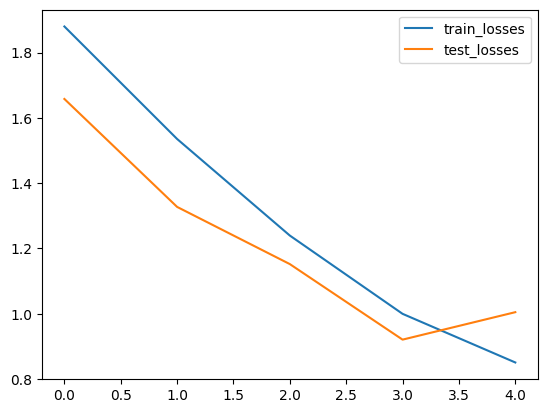

In [ ]:
plt.plot(train_losses, label='train_losses')
plt.plot(test_losses, label='test_losses')
plt.legend()

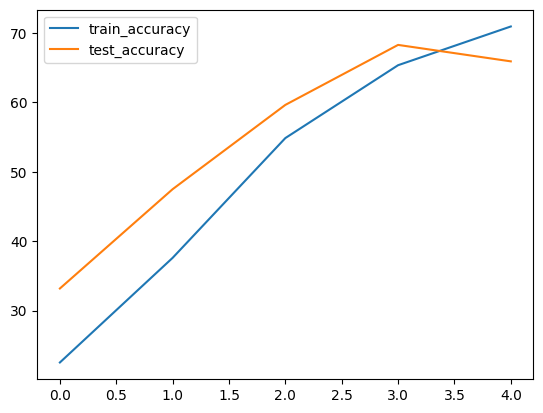

In [ ]:
plt.plot(train_accuracies, label='train_accuracy')
plt.plot(test_accuracies, label='test_accuracy')
plt.legend()

In [ ]:
# Save training results to JSON
import json
from datetime import datetime

results = {
    'model_name': 'VGG19',
    'image_size': 32,
    'max_epoch': max_epoch,
    'train_losses': [float(x) for x in train_losses],
    'train_accuracies': [float(x) for x in train_accuracies],
    'test_losses': [float(x) for x in test_losses],
    'test_accuracies': [float(x) for x in test_accuracies],
    'best_epoch': int(np.argmax(test_accuracies)) + 1,
    'best_test_accuracy': float(max(test_accuracies)),
    'final_train_accuracy': float(train_accuracies[-1]),
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}

results_file = f'VGG19_size32_results.json'
with open(results_file, 'w') as f:
    json.dump(results, f, indent=2)

print(f"\nResults saved to {results_file}")
print(f"Best test accuracy: {results['best_test_accuracy']:.2%} at epoch {results['best_epoch']}")



Results saved to VGG19_size32_results.json
Best test accuracy: 6827.00% at epoch 4
